# Do digital wallet users complain about the same things in different markets?

Analysis of Google Play reviews for **Cash App** (USA), **PayPal** (global),
**Revolut** (Europe) and **Papara** (Turkey).

Pipeline: `src/collect_reviews.py` → `src/clean_reviews.py` → `src/sentiment.py`
→ `src/topics.py`. This notebook only reads the processed tables and reports
aggregates; no review text is printed, so no review content is stored in the
repository.

**Scopes**
- *Cross-market comparison*: the shared 12-month window (31 Oct 2025 - 31 Oct 2026).
  Papara weeks inside the event phases detected in section 6 are excluded, so
  the 2025 legal process does not distort the general picture.
- *Papara event impact*: Papara's full history since January 2025, analysed separately.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import chi2_contingency

from src import analysis as A, charts as C

FIG = Path.cwd().parent / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

def show(chart, name):
    """Save a PNG (for README / GitHub rendering) and display it."""
    path = FIG / f"{name}.png"
    chart.save(path, scale_factor=2)
    display(Image(str(path)))

reviews, complaints = A.load_reviews(), A.load_complaints()
weekly = A.papara_weekly(reviews, complaints)
shocks, phases = A.detect_papara_events(weekly)
reviews = A.add_comparison_scope(reviews, phases)
complaints = A.add_comparison_scope(complaints, phases)

## 1. Data at a glance

In [2]:
ov = A.overview(reviews, complaints)
ov.style.format({"reviews": "{:,}", "clean_reviews": "{:,}", "complaints": "{:,}",
                 "avg_stars": "{:.2f}", "avg_polarity": "{:+.2f}", "complaint_rate": "{:.0%}"})

,app_name,reviews,avg_stars,clean_reviews,avg_polarity,complaints,complaint_rate
app,,,,,,,
cashapp,Cash App,"39,298",4.00,"29,569",+0.13,"10,712",36%
paypal,PayPal,"34,246",3.31,"26,664",-0.18,"15,062",56%
revolut,Revolut,"26,849",4.25,"18,723",+0.26,"5,332",28%
papara,Papara,592,3.33,527,-0.31,355,67%


- `avg_stars` uses every review; `avg_polarity` (-1 … +1, XLM-R) and
  `complaint_rate` use reviews with at least 3 words.
- Papara has far fewer reviews in the comparison scope (event weeks excluded,
  and volume collapsed after the event), so its shares carry wider confidence
  intervals (shown in the dashboard tooltips).

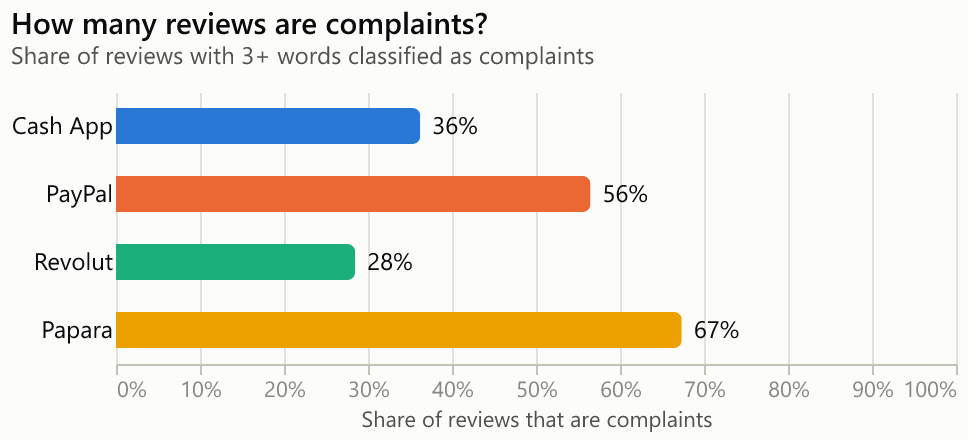

In [3]:
show(C.complaint_rate_bars(ov), "complaint_rate")

## 2. Do markets complain about the same things?

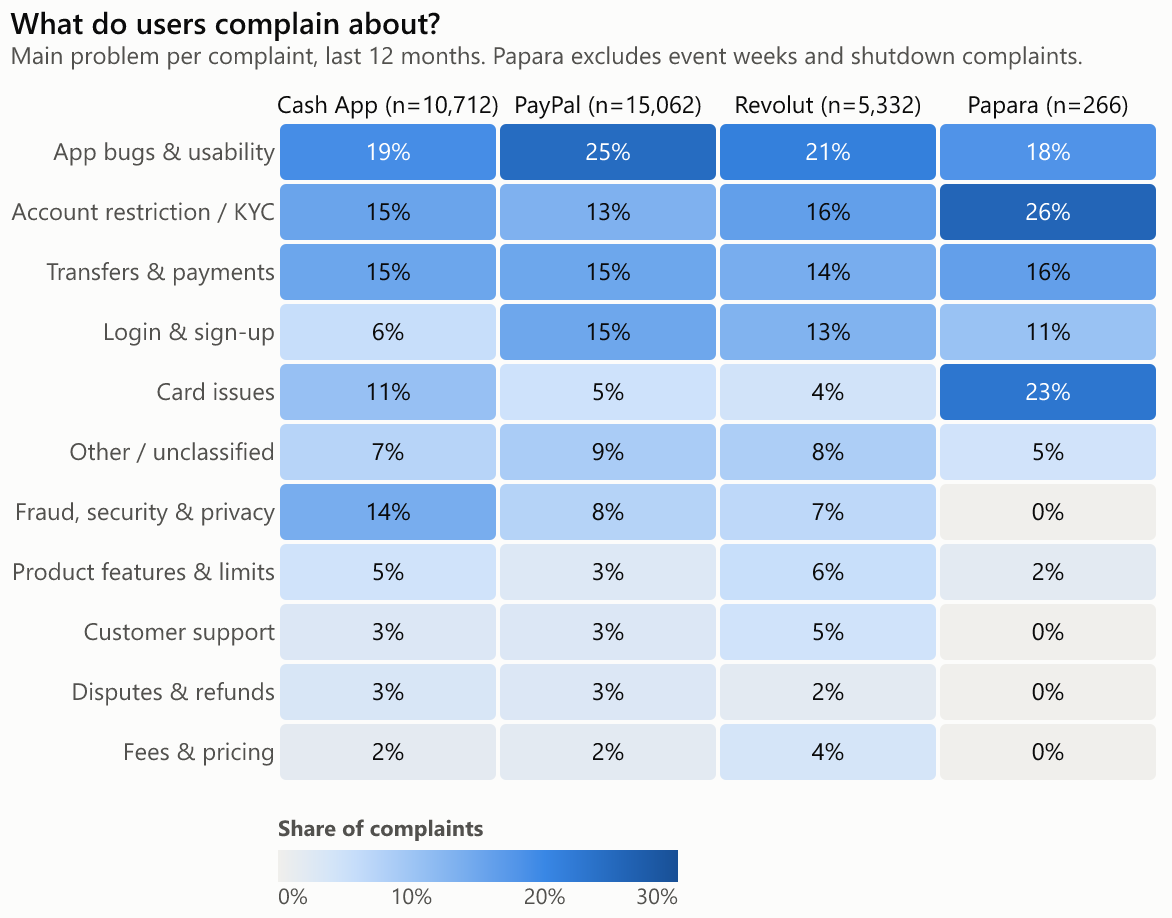

In [4]:
shares = A.category_shares(complaints, exclude=("service_disruption",))
show(C.category_heatmap(shares, "What do users complain about?",
     "Main problem per complaint, last 12 months. Papara excludes event weeks "
     "and shutdown complaints."), "category_heatmap")

In [5]:
en = complaints[complaints["in_comparison"] & (complaints["lang"] == "en")]
table = pd.crosstab(en["category"], en["app"])
chi = chi2_contingency(table)
cramers_v = np.sqrt(chi.statistic / (table.values.sum() * (min(table.shape) - 1)))
print(f"English apps: chi2 = {chi.statistic:,.0f}, p = {chi.pvalue:.1e}, Cramér's V = {cramers_v:.2f}")

top3 = (shares.sort_values("share", ascending=False).groupby("app_name").head(3)
              .groupby("app_name")["category_label"].apply(list))
top3

English apps: chi2 = 1,564, p = 0.0e+00, Cramér's V = 0.16


app_name
Cash App    [App bugs & usability, Account restriction / K...
Papara      [Account restriction / KYC, Card issues, App b...
PayPal      [App bugs & usability, Transfers & payments, L...
Revolut     [App bugs & usability, Account restriction / K...
Name: category_label, dtype: object

**Mostly yes - the same core problems, with a market-specific layer on top.**

- The same three problems sit in the top four in every market:
  **app bugs & usability**, **account restriction / KYC** and
  **transfers & payments**. Together they account for 49-60% of complaints
  in each market.
- The distributions differ statistically (chi-square, p ≈ 0) but the effect is
  small (Cramér's V ≈ 0.16): differences sit in the secondary categories.
- **Cash App** stands out on **fraud & scams** (14% vs 7-8% elsewhere).
- **PayPal** and **Revolut** have far more **login & sign-up** complaints (13-15%)
  than Cash App (6%).
- **Papara** (outside the event) is dominated by **account restriction / KYC**
  (26%, incl. NFC identity checks and the parental-consent flow for under-18s)
  and **card issues** (23%, mostly card delivery).

*Caveat:* each complaint has one main topic, so cross-cutting issues such as
customer support and fees are under-counted (see README).

## 3. Sentiment over time

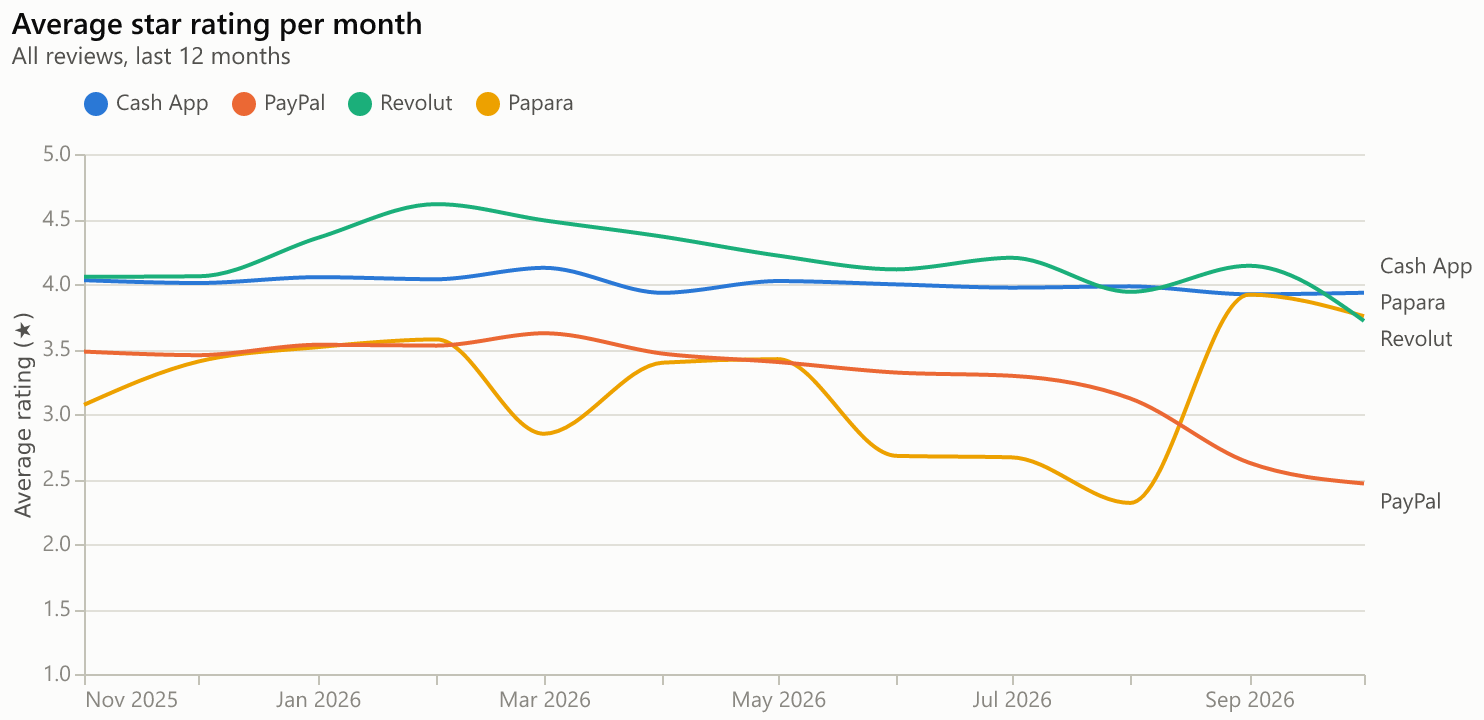

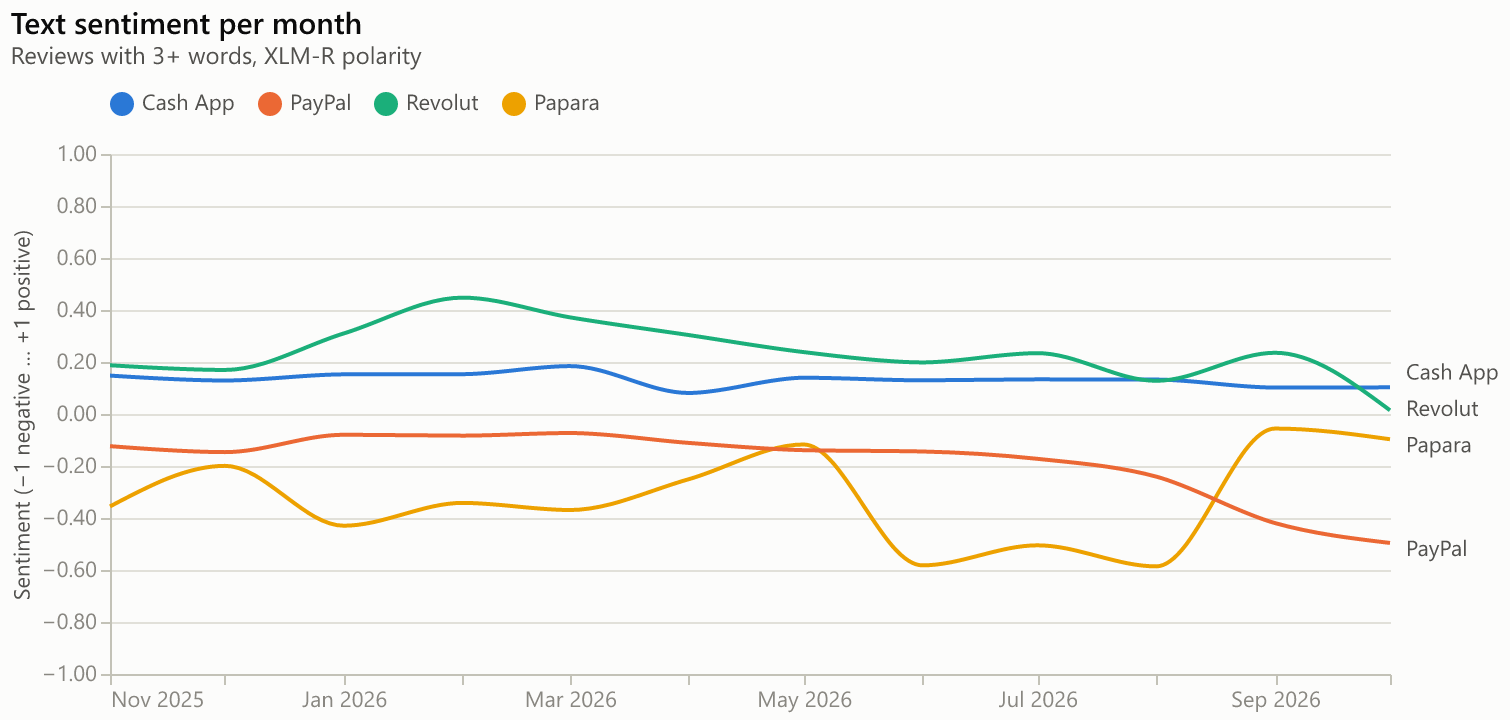

app_name,Cash App,Papara,PayPal,Revolut
period,,,,
2025-11-01,4.03,3.07,3.48,4.06
2025-12-01,4.01,3.40,3.45,4.06
2026-01-01,4.05,3.51,3.53,4.35
2026-02-01,4.04,3.57,3.53,4.61
2026-03-01,4.12,2.85,3.62,4.49
2026-04-01,3.93,3.39,3.46,4.36
2026-05-01,4.02,3.42,3.40,4.22
2026-06-01,4.00,2.68,3.32,4.11
2026-07-01,3.97,2.67,3.29,4.20


In [6]:
trend = A.trend(reviews)
show(C.trend_lines(trend, "avg_stars", "Average star rating per month", "Average rating (★)",
                   (1, 5), ".1f", "All reviews, last 12 months"), "trend_stars")
show(C.trend_lines(trend, "avg_polarity", "Text sentiment per month",
                   "Sentiment (−1 negative … +1 positive)", (-1, 1), ".2f",
                   "Reviews with 3+ words, XLM-R polarity"), "trend_sentiment")
trend.pivot(index="period", columns="app_name", values="avg_stars").round(2)

- **Cash App** is the most stable (≈4.0★ every month).
- **PayPal** declines steadily from 3.6★ in March to 2.5★ in October 2026; text
  sentiment falls from -0.07 to -0.50. Section 4 ties this to the v10 app.
- **Revolut** peaks in February 2026 (4.6★) and drops in October 2026 (3.7★,
  sentiment from +0.24 to +0.01), coinciding with release 10.152.
- **Papara** is volatile on low volume (≈10-40 reviews a month after the event);
  the September 2026 jump is the relaunch described in section 6.

## 4. Version impact

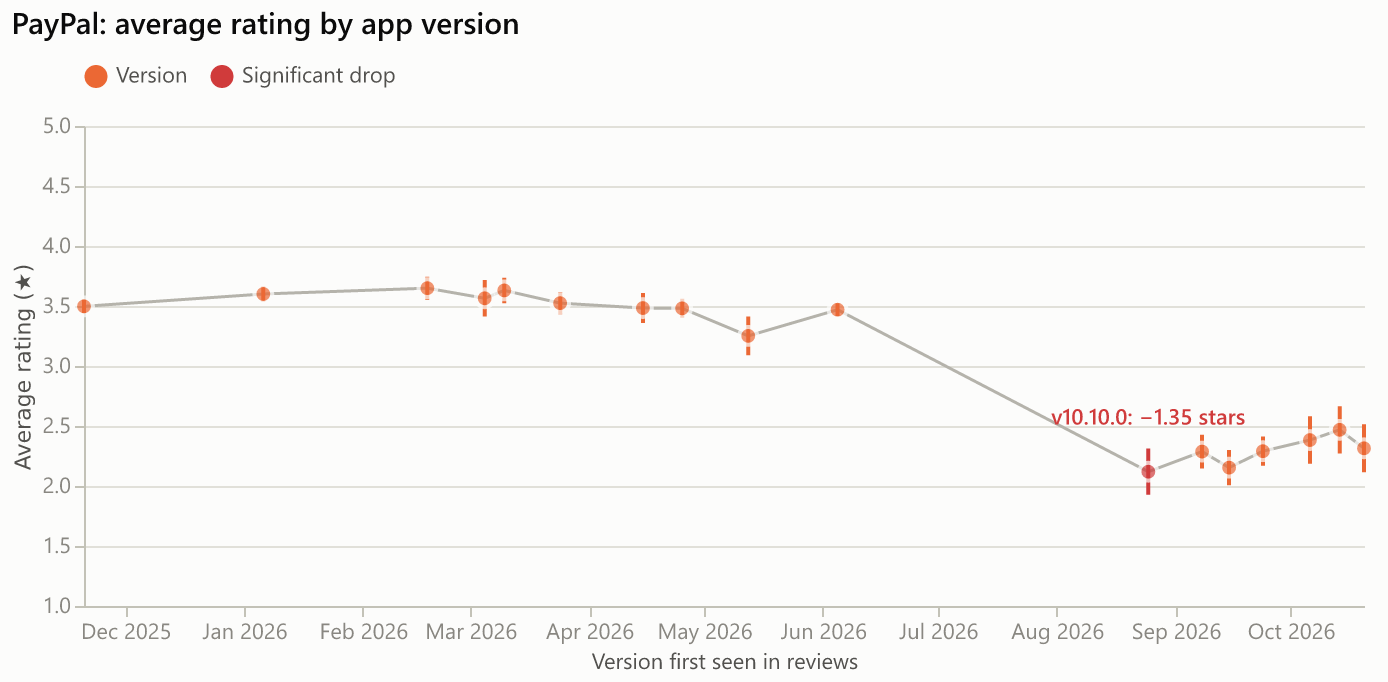

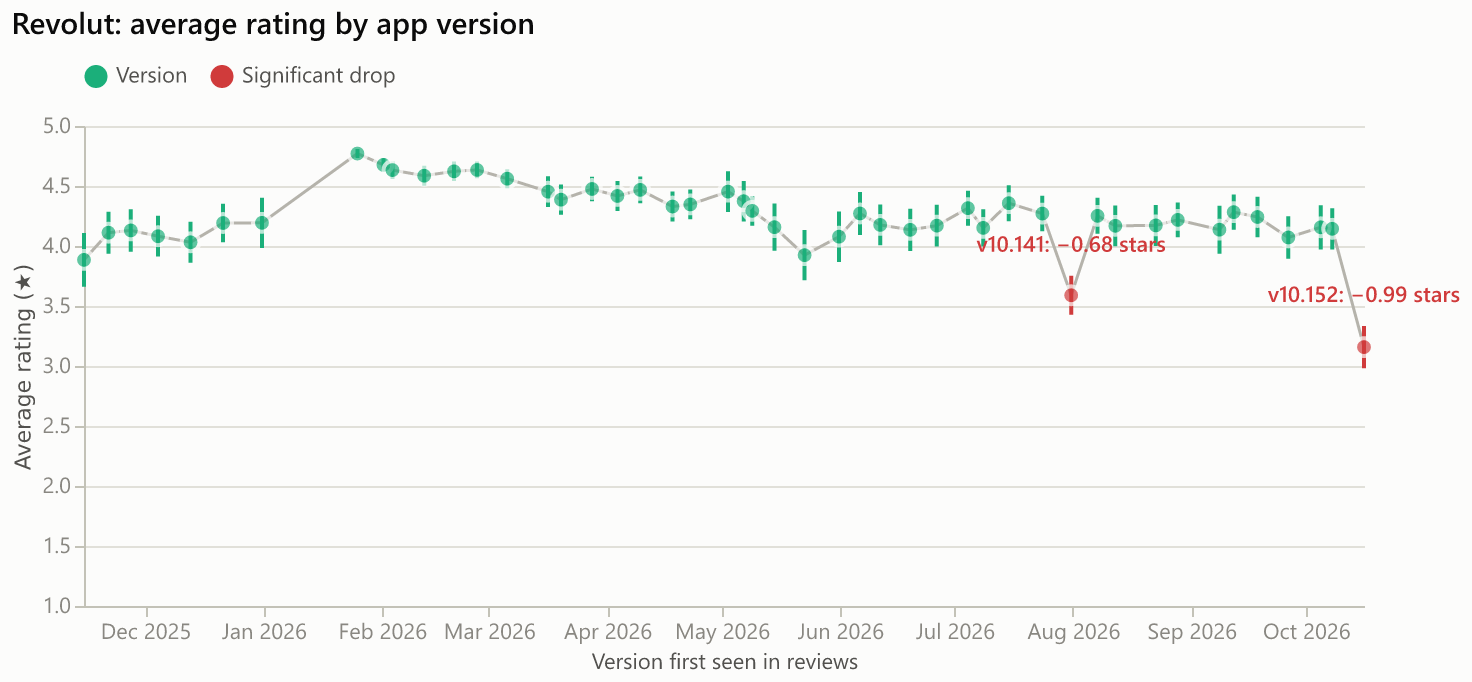

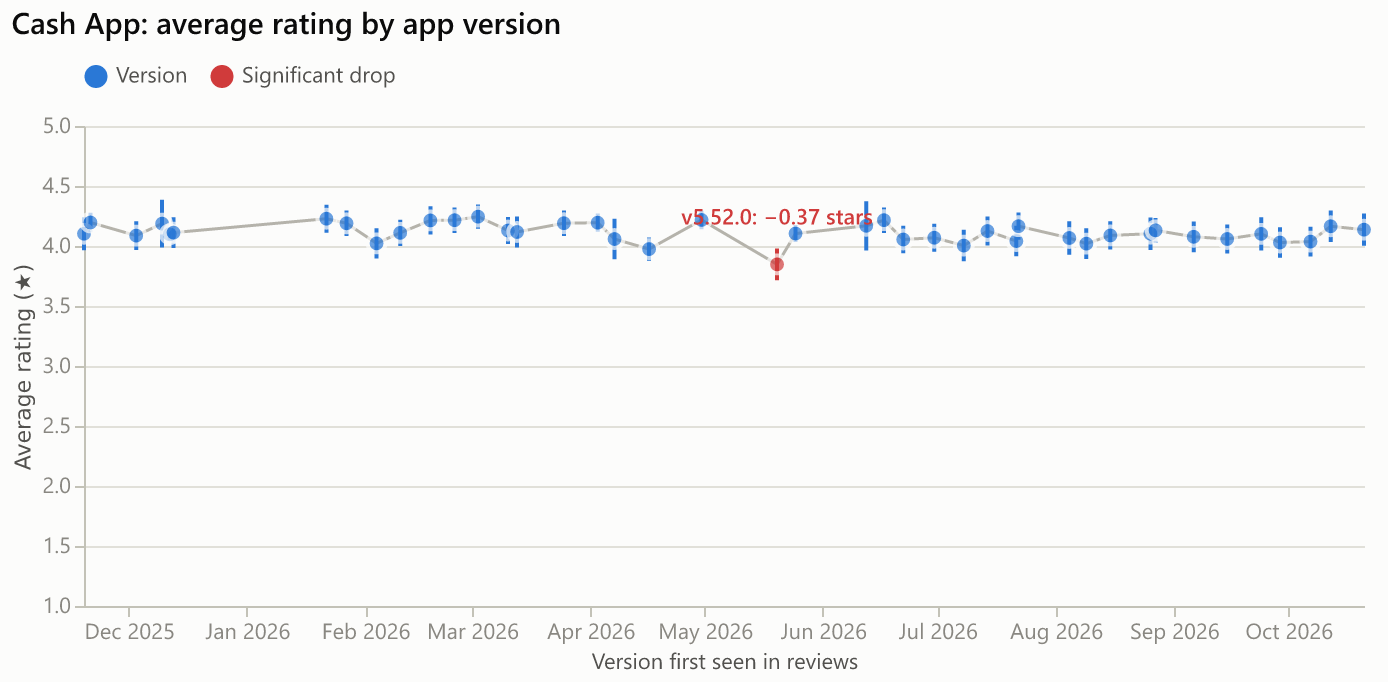

In [7]:
for app in ["paypal", "revolut", "cashapp"]:
    show(C.version_chart(A.version_stats(reviews, complaints, app)), f"versions_{app}")

Same dates since 26 Jun 2026: v8 3.38★ (n=4,368) vs v10 2.29★ (n=3,490), Welch p = 1.5e-159


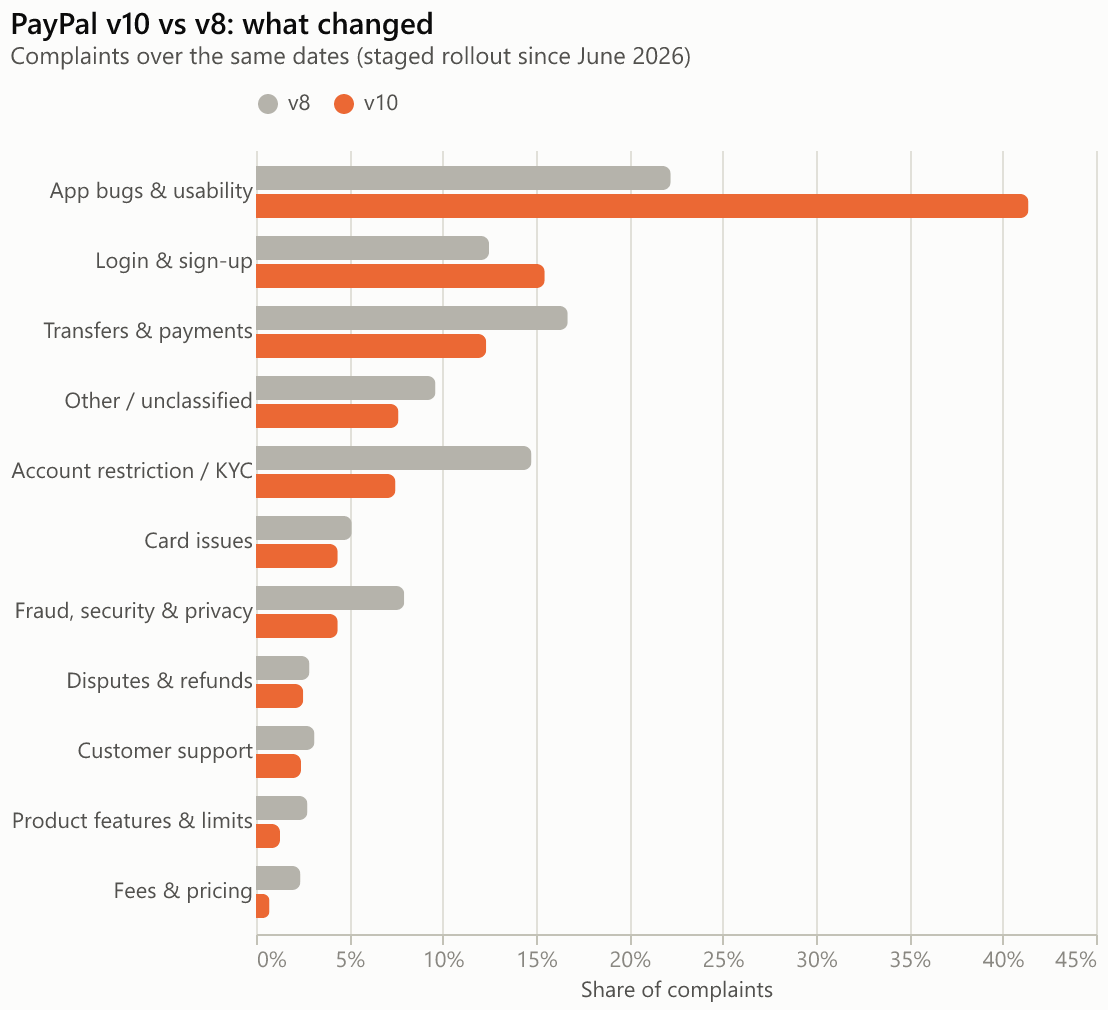

In [8]:
mv = A.major_version_comparison(reviews, complaints, "paypal", "8", "10")
print(f"Same dates since {mv['since']:%d %b %Y}: v8 {mv['stars']['8']:.2f}★ (n={mv['n']['8']:,}) "
      f"vs v10 {mv['stars']['10']:.2f}★ (n={mv['n']['10']:,}), Welch p = {mv['p_value']:.1e}")
show(C.paired_bars(mv["category_shares"], "8", "10", "paypal", "PayPal v10 vs v8: what changed",
                   "Complaints over the same dates (staged rollout since June 2026)"),
     "paypal_v8_v10")

**PayPal v10 is the clearest version effect in the data.** It was rolled out
gradually from late June 2026, so v8 and v10 were in use at the same time -
comparing them over the same dates rules out seasonal or news-driven effects.
v10 users rate the app about **1.1 stars lower**, and **app bugs & usability**
nearly doubles as a share of complaints (≈22% → ≈41%).

Smaller, significant drops (≥0.3★, p < 0.01 versus the previous version):
**Revolut 10.141** (Aug 2026, -0.7★) and **10.152** (Oct 2026, -1.0★), and
**Cash App 5.52.0** (May 2026, -0.4★, card complaints up).

## 5. Where each app leads or lags

Each app is compared with the other apps combined. Categories are measured as
**complaints per 100 reviews with text** (how often users hit a problem), not
as a share of complaints, so an app with few complaints overall is not
penalised for a high share in one category. A difference is *notable* only if
it is statistically clear (p < 0.01) and practically large: ≥1.5× and ≥1
complaint per 100 reviews for categories; ≥0.3★ for rating; ≥5 points for
complaint rate; ≥15 points for reply rate; ≥2× for median reply time. Papara
is compared only on the 6 categories its Turkish topic model measures reliably.

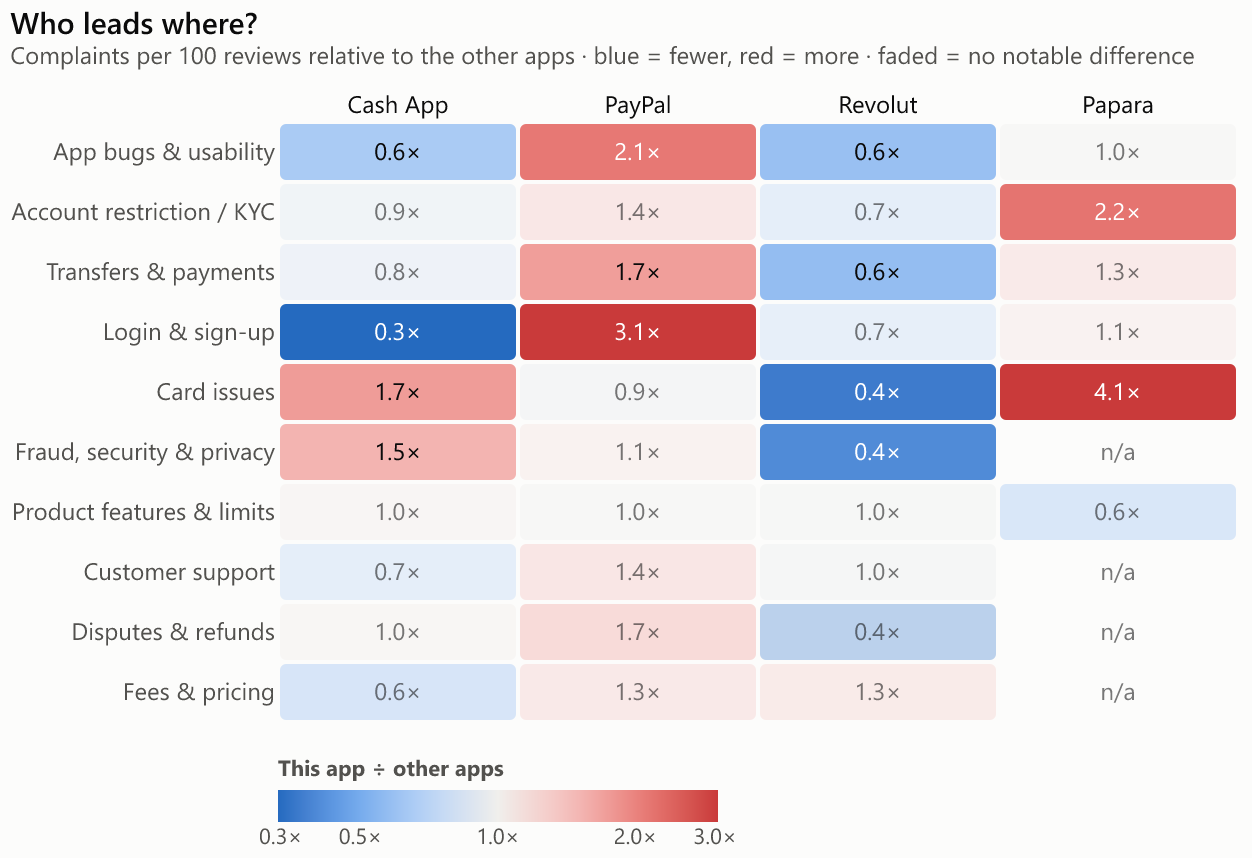

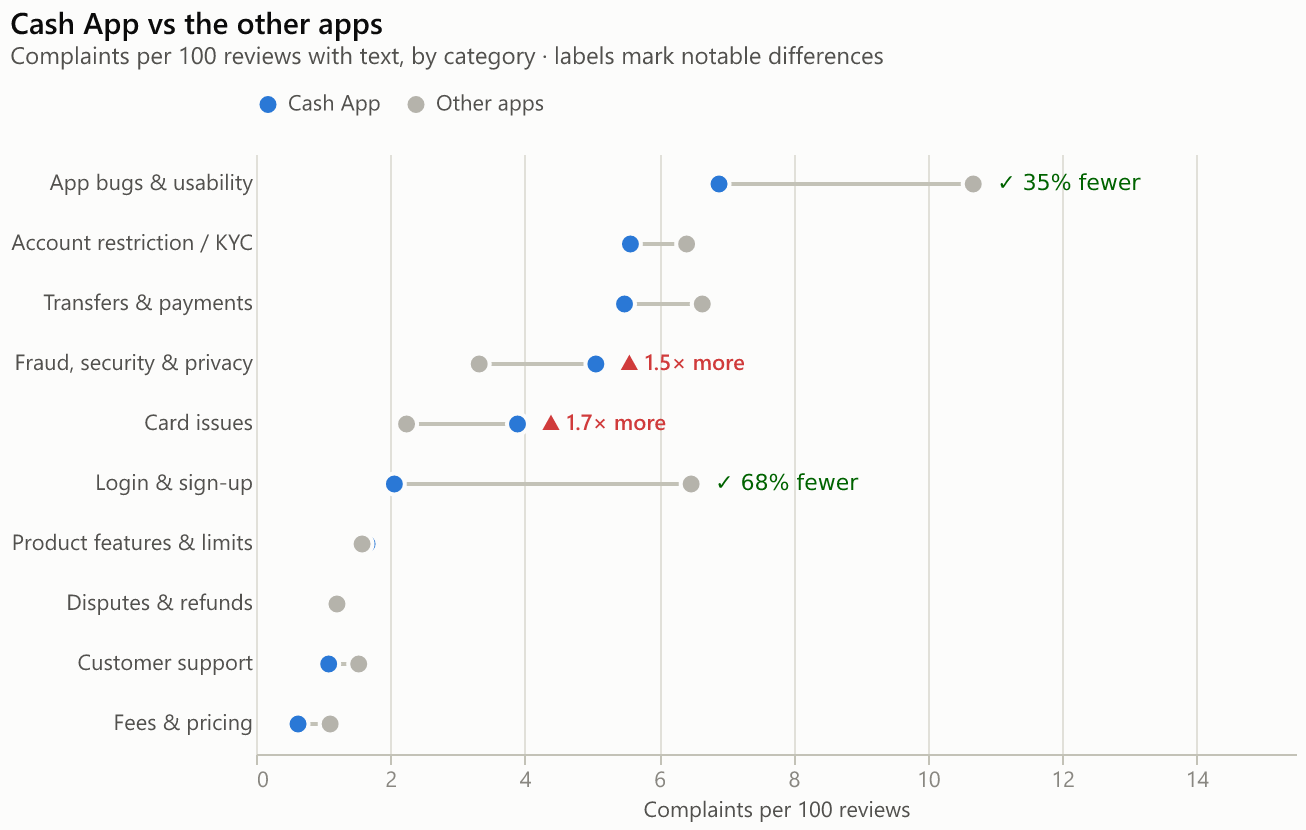

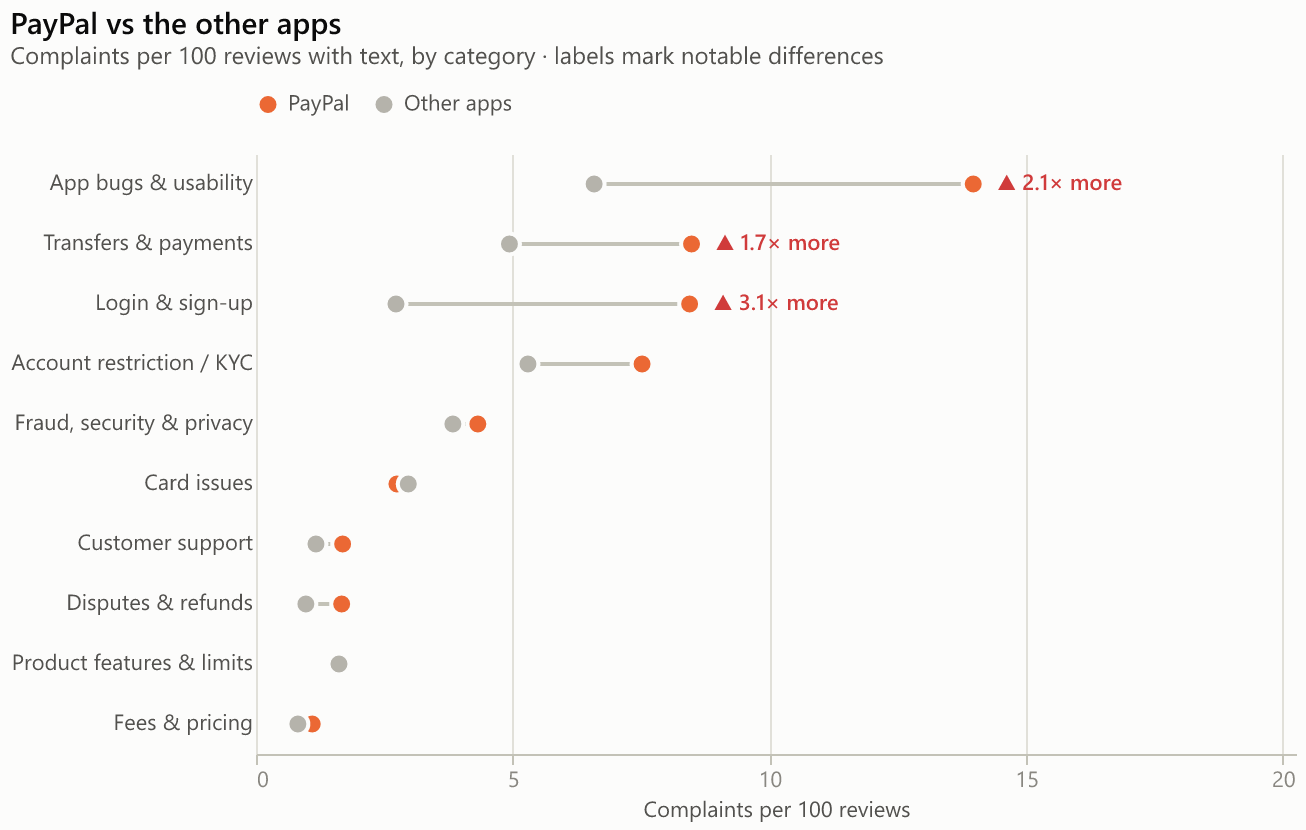

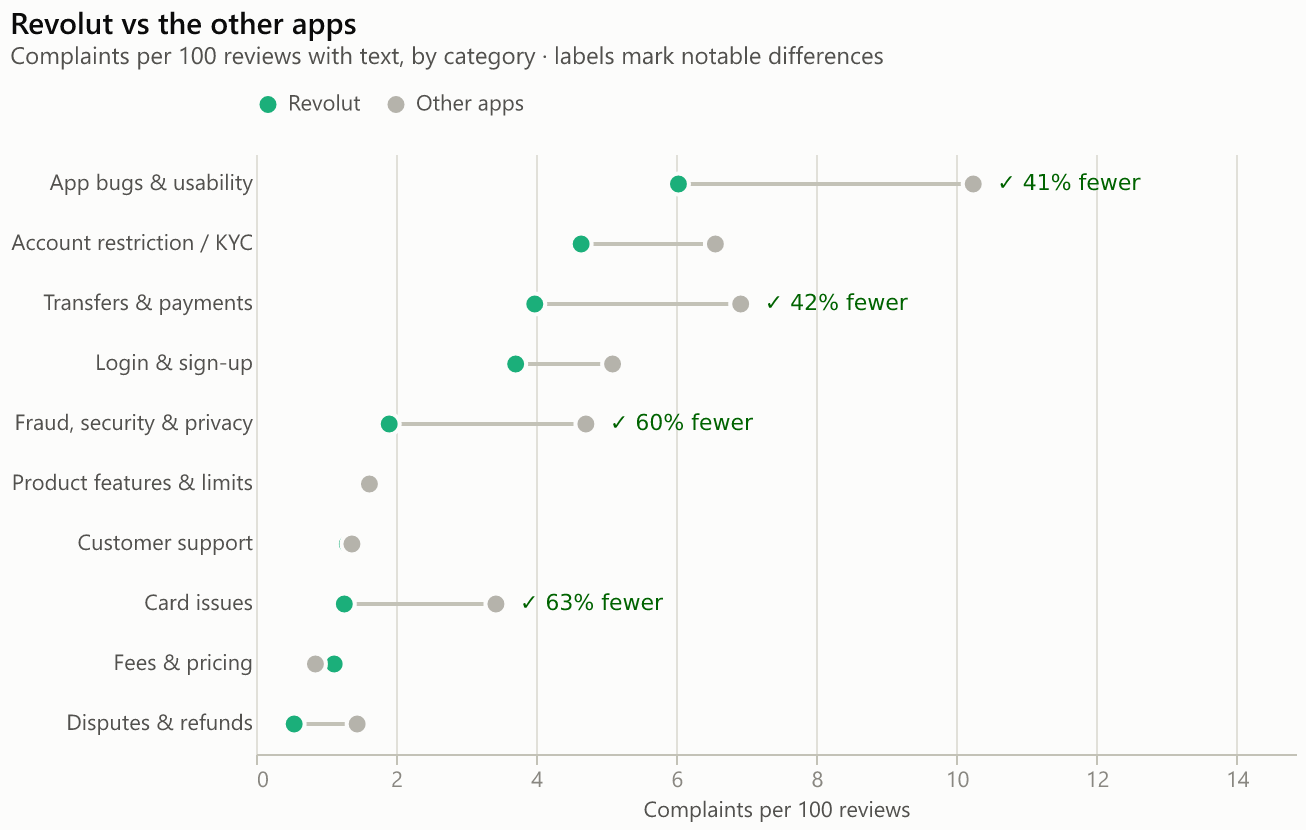

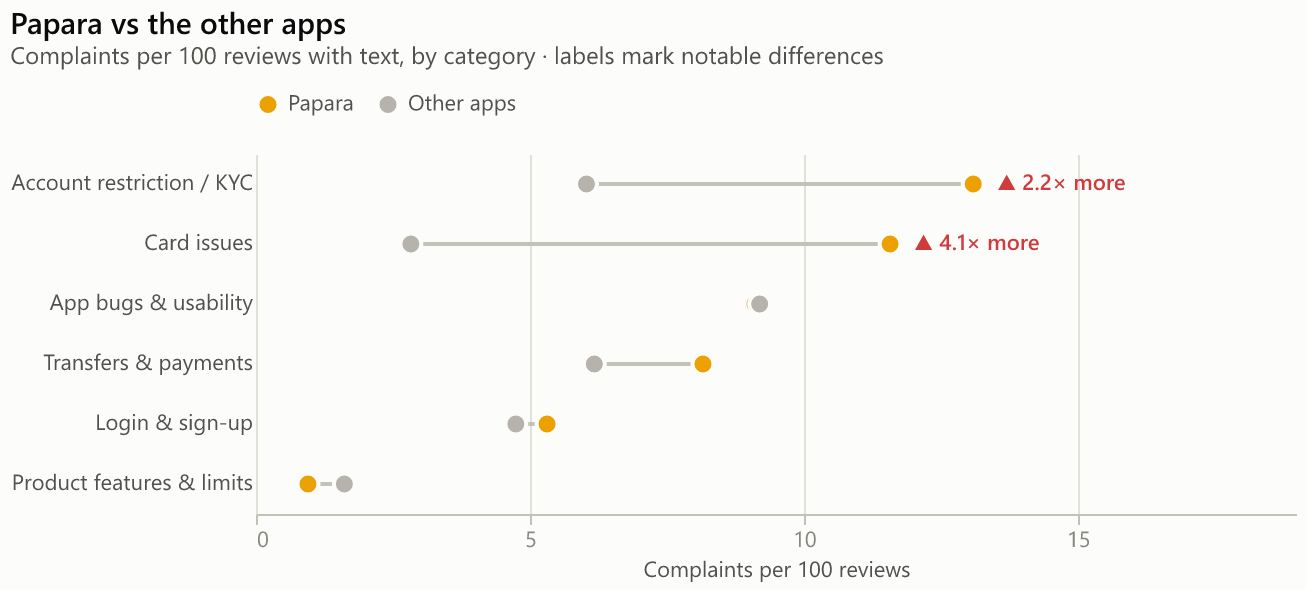

In [9]:
sw = A.strengths_weaknesses(reviews, complaints)
show(C.strengths_matrix(sw), "strengths_matrix")
for app in A.APP_ORDER:
    show(C.strengths_dumbbell(sw, app), f"strengths_{app}")

In [10]:
notable = sw[sw["notable"]].assign(direction=lambda d: d["better"].map({True: "leads", False: "lags"}))
notable[["app_name", "direction", "kind", "key", "value", "others", "ratio"]].sort_values(
    ["app_name", "direction"]).round(2)

,app_name,direction,kind,key,value,others,ratio
3,Cash App,lags,overall,reply_hours,6.73,0.43,15.74
6,Cash App,lags,category,card,3.89,2.24,1.74
11,Cash App,lags,category,fraud_security,5.06,3.32,1.52
1,Cash App,leads,overall,complaint_rate,0.36,0.45,0.80
2,Cash App,leads,overall,reply_rate,0.86,0.19,4.48
5,Cash App,leads,category,app_bugs,6.89,10.68,0.65
12,Cash App,leads,category,login_access,2.06,6.48,0.32
41,Papara,lags,overall,avg_stars,3.33,3.83,0.87
42,Papara,lags,overall,complaint_rate,0.67,0.41,1.62
44,Papara,lags,overall,reply_hours,20.85,3.13,6.67


- **Revolut leads on almost everything**: highest rating, lowest complaint rate,
  fastest replies (median 25 minutes), and 40-63% fewer complaints about app
  bugs, cards, fraud and transfers. No notable weakness.
- **Cash App** replies to 86% of complaints (others: 19%) and has 68% fewer
  login problems and 35% fewer app-bug complaints, but 1.5× more fraud and
  1.7× more card complaints, and it replies slower than Revolut.
- **PayPal** lags everywhere it differs: it replies to about 1% of complaints
  (others: 80%), and has 3.1× more login, 2.1× more app-bug and 1.7× more
  transfer complaints per review.
- **Papara** (outside event weeks) has 4.1× more card and 2.2× more
  account/KYC complaints and the slowest replies (median 21 hours).

*Reply data* come from developer replies shown on Google Play. Reply times are
measured from a review's last edit, so edited reviews (negative times) are left out.

## 6. Papara: event impact (kept separate from the comparison)

Event phases are **detected from the data**, not set by hand (`src/analysis.py`):

- a **shock** week has at least 1.75× the median review volume of the previous
  8 weeks (and ≥50 reviews) **and** the complaint share or the
  shutdown/regulatory share rises by ≥20 points; each shock opens an 8-week
  crisis window, and a shock inside an open window extends it;
- a **relaunch** week after the last crisis has ≥2.5× the previous median
  volume **and** a rating ≥0.75★ above the previous mean.

In [11]:
pd.DataFrame([{"phase": p.name, "start": p.start.date(), "end (excl.)": p.end.date(),
               "excluded from comparison": p.is_event} for p in phases])

,phase,start,end (excl.),excluded from comparison
0,Before the event,2024-12-29,2025-05-25,False
1,Shock 1,2025-05-25,2025-07-20,True
2,Between shocks 1 and 2,2025-07-20,2025-10-26,True
3,Shock 2,2025-10-26,2025-12-28,True
4,After the event,2025-12-28,2026-09-13,False
5,Relaunch,2026-09-13,2026-11-01,False


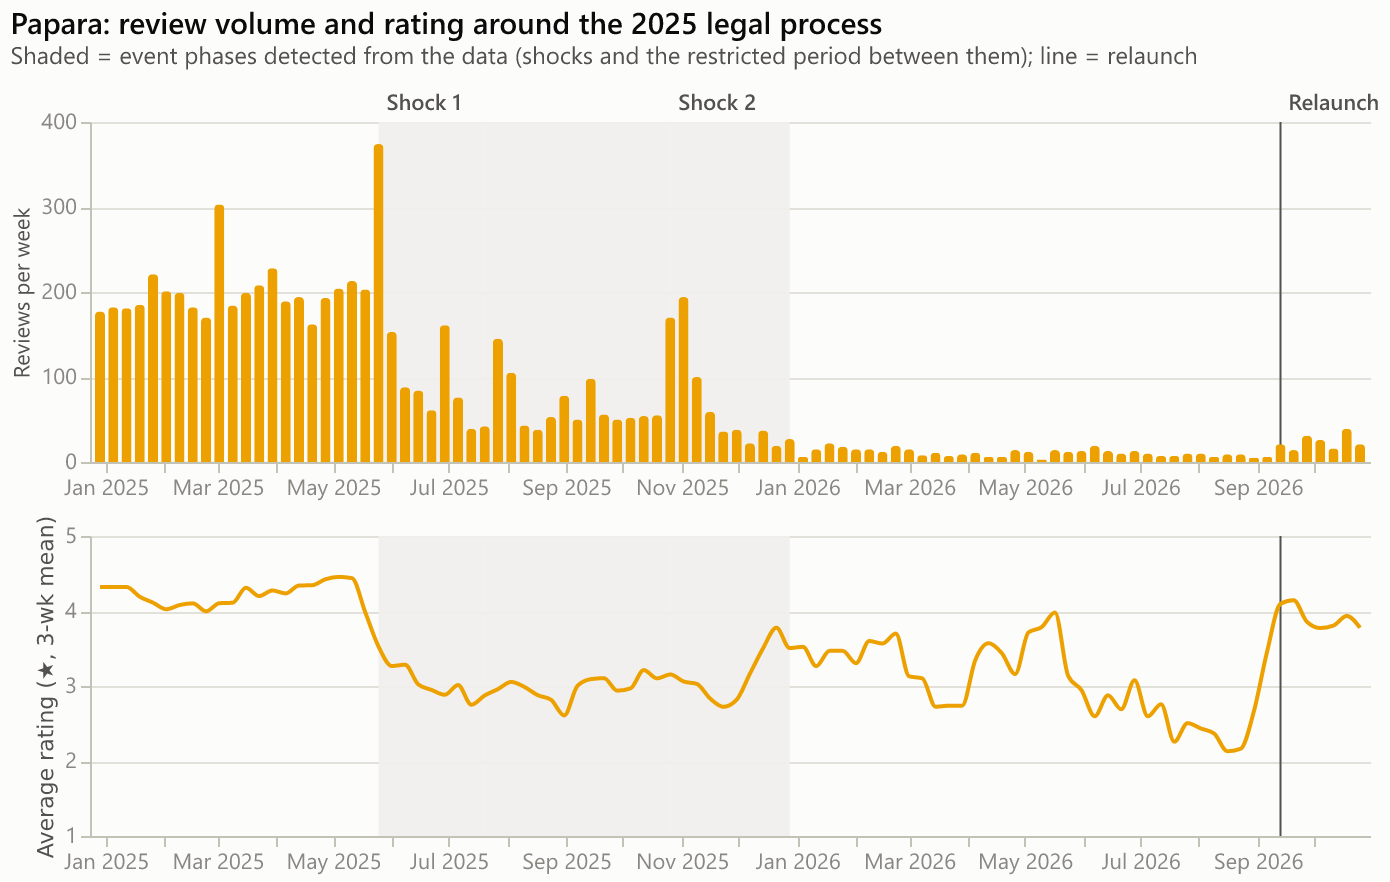

In [12]:
show(C.papara_timeline(weekly, phases), "papara_timeline")

In [13]:
summary = A.phase_summary(reviews, complaints, phases)
summary.style.format({"reviews_per_week": "{:.0f}", "avg_stars": "{:.2f}",
                      "avg_polarity": "{:+.2f}", "complaint_rate": "{:.0%}",
                      "shutdown_share": "{:.0%}", "five_star_complaints": "{:.0%}"})

,phase,start,end,reviews_per_week,avg_stars,avg_polarity,complaint_rate,shutdown_share,five_star_complaints
0,Before the event,2024-12-29,2025-05-25,199,4.23,+0.12,40%,16%,25%
1,Shock 1,2025-05-25,2025-07-20,130,3.12,-0.45,77%,26%,29%
2,Between shocks 1 and 2,2025-07-20,2025-10-26,66,3.05,-0.41,75%,18%,26%
3,Shock 2,2025-10-26,2025-12-28,75,3.07,-0.33,72%,44%,31%
4,After the event,2025-12-28,2026-09-13,11,3.12,-0.40,74%,25%,28%
5,Relaunch,2026-09-13,2026-11-01,24,3.86,-0.07,51%,24%,31%


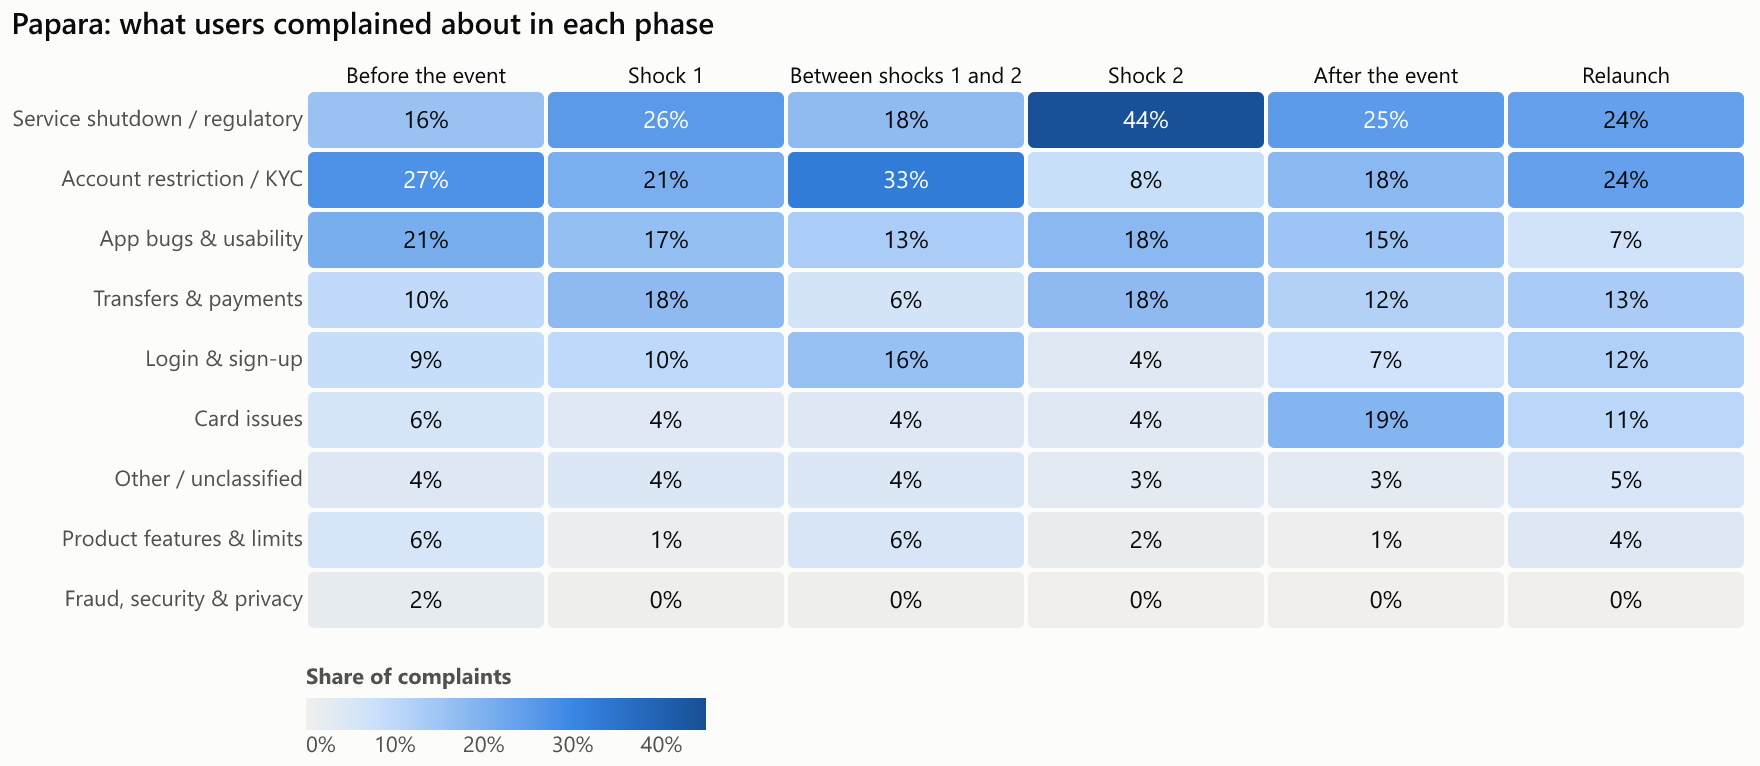

In [14]:
show(C.phase_heatmap(A.phase_category_shares(complaints, phases)), "papara_phases")

- **Before the event** (Jan - May 2025): ≈200 reviews a week, 4.2★, 40% of
  reviews are complaints.
- **Shock 1** (late May 2025): volume doubles in one week, the rating drops to
  3.1★ and the complaint rate to 77%. Transfer complaints almost double.
- **Between the shocks**: restricted operations - account restriction / KYC
  peaks at 33% of complaints.
- **Shock 2** (late Oct 2025): shutdown/regulatory complaints jump to 44%
  ("give my money back", "the licence was revoked").
- **After the event**: volume collapses to ≈11 reviews a week; card delivery
  becomes a top complaint.
- **Relaunch** (Sep 2026): the rating recovers to 3.9★ and the complaint rate
  falls to 51%, but both remain worse than before the event.

About a quarter to a third of Papara complaints in every phase are 5-star
reviews ("I gave 5 stars so this shows at the top"), which is why text
sentiment rather than the star rating is used to identify complaints.

*Measurement note:* the shutdown/regulatory category is already 16% before
the event because the Turkish topic model groups some generic distrust
complaints into it; read the event effect as the rise above that baseline.

## 7. Summary

| App | Main problems (share of complaints) | Distinctive issue |
|---|---|---|
| Cash App | app bugs 19%, account restriction 15%, transfers 15% | fraud & scams 14% |
| PayPal | app bugs 25%, transfers 15%, login 15% | v10 app: -1.1★ vs v8 |
| Revolut | app bugs 21%, account restriction 16%, transfers 14% | login & ID verification |
| Papara | account restriction 26%, card 23%, app bugs 18% | 2025 legal process and relaunch |

**Limitations**
- One topic per complaint: customer support and fees are under-counted.
- Google Play only; reviewers are self-selected and skew towards extremes.
- Papara's comparison sample is small (n = 266 complaints outside event weeks).
- English reviews of Revolut come from a UK storefront query; Google Play
  returns reviews by language more than by country.